# Simulated Data

In [1]:
from STalign import STalign
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import plotly
import requests
import scanpy as sc
import matplotlib
import os

import warnings
warnings.filterwarnings("ignore")

## Load Data

In [2]:
# load Merfish mouse brain 33 data
in_ = '/hpc/group/hickeylab/fl135/pkl_data/'

i = 24
file_path = in_ + 'merfish_mouse_brain_slice' + str(i) + '.h5ad'
ad = sc.read(file_path)
ad.obs['original_clusters']=ad.obs['spa_cluster'].astype('category')
ad.obsm['spatial'] = ad.obsm['spatial'].to_numpy()[:, :2]
ad

AnnData object with n_obs × n_vars = 4052 × 254
    obs: 'sample_id', 'slice_id', 'class_label', 'subclass', 'label', 'Astro_1', 'Endo', 'SMC', 'L23_IT_3', 'VLMC', 'L6_CT_5', 'L45_IT_2', 'L45_IT_SSp_2', 'Peri', 'L5_ET_1', 'L45_IT_1', 'L45_IT_5', 'L45_IT_3', 'L23_IT_4', 'L5_IT_1', 'Micro_1', 'L23_IT_2', 'L5_ET_5', 'Sst_3', 'L6_IT_3', 'Oligo_1', 'L5_ET_4', 'Sncg_1', 'L6_IT_Car3', 'Vip_7', 'PVM', 'L5_ET_3', 'L56_NP_1', 'Pvalb_6', 'L6_CT_3', 'L5_IT_2', 'L6_CT_1', 'L45_IT_SSp_1', 'Astro_2', 'Pvalb_5', 'L56_NP_2', 'Oligo_2', 'L6_IT_1', 'L6_CT_2', 'Pvalb_3', 'OPC', 'striatum_1', 'L5_IT_3', 'L23_IT_1', 'Oligo_3', 'Pvalb_4', 'Vip_1', 'L23_IT_5', 'L6_CT_6', 'Pvalb_1', 'Pvalb_7', 'L5_IT_4', 'L6b_2', 'L6_CT_4', 'Vip_3', 'Vip_10', 'striatum_2', 'Sst_2', 'L6_IT_2', 'L6b_1', 'L6_CT_8', 'Pvalb_10', 'L5_ET_2', 'L6_CT_7', 'Micro_2', 'L45_IT_4', 'Sst_1', 'Pvalb_2', 'Vip_6', 'Lamp5_1', 'L6b_3', 'ventricle_1', 'Lamp5_5', 'Sncg_2', 'Sst_6', 'Vip_8', 'Sst_5', 'Sst_4', 'Astro_3', 'Vip_2', 'Pvalb_8', 'Lamp5_9'

In [3]:
file_path = in_ + 'merfish_mouse_brain_slice' + str(i-1) + '.h5ad'
ad_target = sc.read(file_path)
ad_target.obs['original_clusters']=ad_target.obs['spa_cluster'].astype('category')
ad_target.obsm['spatial'] = ad_target.obsm['spatial'].to_numpy()[:, :2]
ad_target

AnnData object with n_obs × n_vars = 5375 × 254
    obs: 'sample_id', 'slice_id', 'class_label', 'subclass', 'label', 'Astro_1', 'Endo', 'SMC', 'L23_IT_3', 'VLMC', 'L6_CT_5', 'L45_IT_2', 'L45_IT_SSp_2', 'Peri', 'L5_ET_1', 'L45_IT_1', 'L45_IT_5', 'L45_IT_3', 'L23_IT_4', 'L5_IT_1', 'Micro_1', 'L23_IT_2', 'L5_ET_5', 'Sst_3', 'L6_IT_3', 'Oligo_1', 'L5_ET_4', 'Sncg_1', 'L6_IT_Car3', 'Vip_7', 'PVM', 'L5_ET_3', 'L56_NP_1', 'Pvalb_6', 'L6_CT_3', 'L5_IT_2', 'L6_CT_1', 'L45_IT_SSp_1', 'Astro_2', 'Pvalb_5', 'L56_NP_2', 'Oligo_2', 'L6_IT_1', 'L6_CT_2', 'Pvalb_3', 'OPC', 'striatum_1', 'L5_IT_3', 'L23_IT_1', 'Oligo_3', 'Pvalb_4', 'Vip_1', 'L23_IT_5', 'L6_CT_6', 'Pvalb_1', 'Pvalb_7', 'L5_IT_4', 'L6b_2', 'L6_CT_4', 'Vip_3', 'Vip_10', 'striatum_2', 'Sst_2', 'L6_IT_2', 'L6b_1', 'L6_CT_8', 'Pvalb_10', 'L5_ET_2', 'L6_CT_7', 'Micro_2', 'L45_IT_4', 'Sst_1', 'Pvalb_2', 'Vip_6', 'Lamp5_1', 'L6b_3', 'ventricle_1', 'Lamp5_5', 'Sncg_2', 'Sst_6', 'Vip_8', 'Sst_5', 'Sst_4', 'Astro_3', 'Vip_2', 'Pvalb_8', 'Lamp5_9'

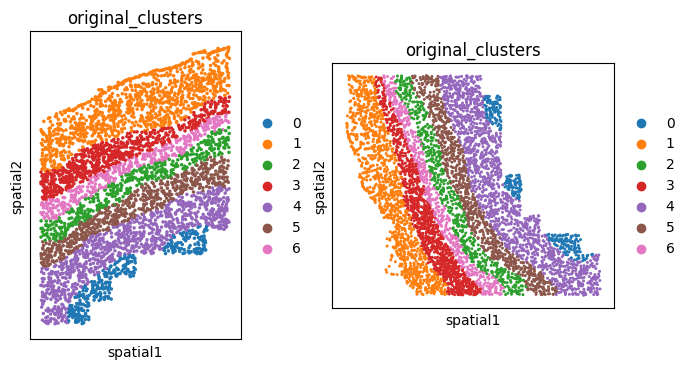

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

sc.pl.spatial(ad, color='original_clusters', spot_size=30, ax=axes[0], show=False)
sc.pl.spatial(ad_target, color='original_clusters', spot_size=30, ax=axes[1], show=False)
plt.show()

In [5]:
spatial_coords_target = ad_target.obsm['spatial']
x_target = spatial_coords_target[:, 0]
y_target = -spatial_coords_target[:, 1]

# fig,ax = plt.subplots()

# rasterize at 30um resolution (assuming positions are in um units) and plot
XJ,YJ,J = STalign.rasterize(x_target,y_target,dx=20,blur=1.5, draw=False)

In [6]:
spatial_coords = ad.obsm['spatial']
x = spatial_coords[:, 1]
y = spatial_coords[:, 0]

# rasterize at 30um resolution (assuming positions are in um units) and plot
XI,YI,I = STalign.rasterize(x,y,dx=20,blur=1.5,draw=False)

In [7]:
x_target = x_target -1300
y_target = y_target -2000

x = x +2000
y = y -5700

In [8]:
# rasterize at 30um resolution (assuming positions are in um units) and plot
XI,YI,I = STalign.rasterize(x,y,dx=20,blur=1.5,draw=False)
XJ,YJ,J = STalign.rasterize(x_target,y_target,dx=20,blur=1.5,draw=False)

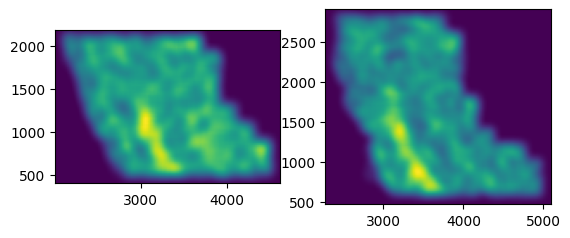

In [9]:
# get extent of images
extentI = STalign.extent_from_x((YI,XI))
extentJ = STalign.extent_from_x((YJ,XJ))

# plot rasterized images
fig,ax = plt.subplots(1,2)
ax[0].imshow(I[0], extent=extentI)
ax[1].imshow(J[0], extent=extentJ)
ax[0].invert_yaxis()
ax[1].invert_yaxis()

CPU times: user 7min 34s, sys: 15.3 s, total: 7min 50s
Wall time: 7min 55s


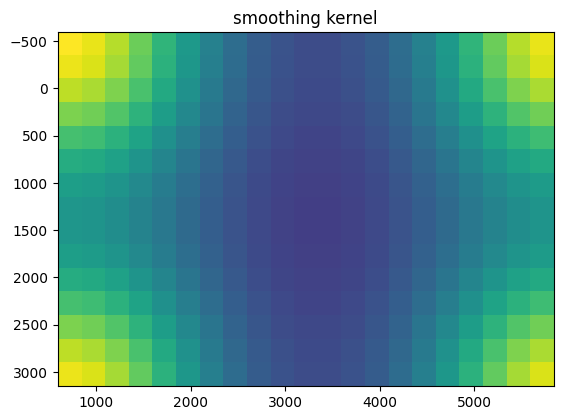

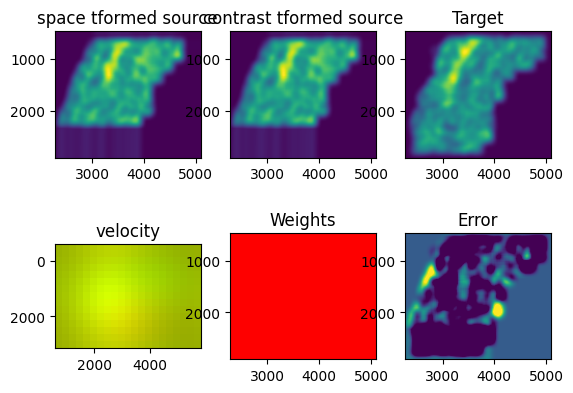

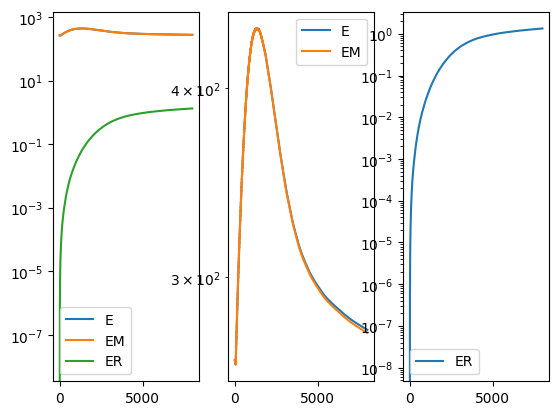

In [10]:
%%time
# run LDDMM
# specify device (default device for STalign.LDDMM is cpu)
if torch.cuda.is_available():
    device = 'cuda:0'
else:
    device = 'cpu'

# keep all other parameters default
params = {
            # 'niter':10000,
            # 'pointsI':pointsI,
            # 'pointsJ':pointsJ,
            # 'L':L,'T':T,
            'niter':8000,
            'device':device,
            'epV': 20,
            'sigmaA': 1, #standard deviation of artifact intensities
            'sigmaB': 1, #standard deviation of background intensities
            'sigmaM': 1, #standard deviation of matching tissue intenities
          }

out = STalign.LDDMM([YI,XI],I,[YJ,XJ],J,**params)

In [11]:
# get necessary output variables
A = out['A']
v = out['v']
xv = out['xv']


In [12]:
# apply transform to original points
tpointsI= STalign.transform_points_source_to_target(xv,v,A, np.stack([y, x], 1).astype(np.float64))

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()

#switch from row column coordinates (y,x) to (x,y)
xI_LDDMM = tpointsI[:,1]
yI_LDDMM = tpointsI[:,0]

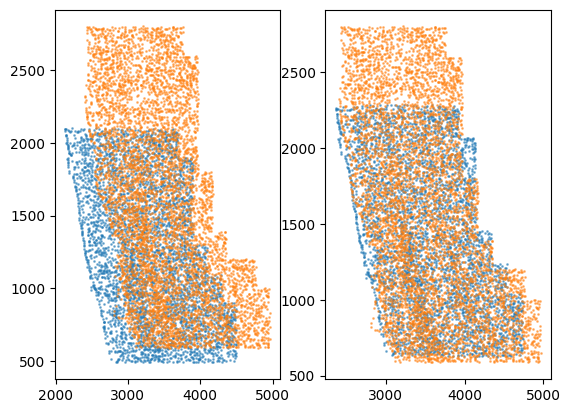

In [13]:
fig,ax = plt.subplots(1,2)
ax[0].scatter(x,y,s=1,alpha=0.5, label='source with initial affine transformation')
ax[0].scatter(x_target,y_target,s=1,alpha=0.5, label='target')
ax[1].scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.5, label = 'source STaligned')
ax[1].scatter(x_target,y_target,s=1,alpha=0.5, label='target')
# ax[0].legend(markerscale = 10, loc = 'lower left')
# ax[1].legend(markerscale = 10, loc = 'lower left')

In [14]:
from sklearn.metrics import pairwise

f1 = np.column_stack((x_target, y_target))  # Shape: (n_points, 2)
f2 = np.column_stack((xI_LDDMM, yI_LDDMM))  # Shape: (n_points, 2)
alignment = pairwise.euclidean_distances(f1, f2)
alignment = np.exp(-alignment)

alignment_df = pd.DataFrame(alignment)


In [15]:
# Save as .pkl
alignment_df.to_pickle("23_24_AlignmentPi.pkl")

## LAA

In [16]:
def cal_layer_based_alignment_result_mHypothalamus(alignment, s1, s2):
    #fei added
    labels = []
    labels.extend(s1.obs['original_clusters'])
    labels.extend(s2.obs['original_clusters'])

    res = []
    #l_dict = {"0": 0, "1": 1, "2": 2, "3": 3, "4": 4, "5": 5, "6": 6}
    cnt0 = 0
    ir = 0
    max_smallerThan0 = []
    sum_smallerThan0 = []
    min_smallerThan0 = []

    for i, elem in enumerate(alignment):
        #if np.sum(elem)>0:
        if np.max(elem) - np.min(elem) != 0:
            if labels[i] == labels[elem.argmax() + alignment.shape[0]]:
                cnt0 += 1
        else:
            ir += 1
            max_smallerThan0.append(np.max(elem))
            sum_smallerThan0.append(np.sum(elem))
            min_smallerThan0.append(np.min(elem))
    print("the number of sum alignment equals 0:", str(cnt0))
    if len(sum_smallerThan0)>0:
        print("sum in sum alignment equals 0 is between", np.min(sum_smallerThan0), np.max(sum_smallerThan0))
        print("max in sum alignment equals 0 is between", np.min(max_smallerThan0), np.max(max_smallerThan0))
        print("min in sum alignment equals 0 is between", np.min(min_smallerThan0), np.max(min_smallerThan0))
    res.extend([cnt0])
    return res

In [17]:
res = cal_layer_based_alignment_result_mHypothalamus(alignment, ad, ad_target)
res[0]/len(ad.obs['original_clusters'])

the number of sum alignment equals 0: 941


0.2322309970384995

In [83]:
alignment.shape

(3611, 3596)

## ARI

In [18]:
from sklearn.metrics import adjusted_rand_score


def compute_alignment_ari(sliceA, sliceB, pi):
    mapped_clusters = []
    for j in range(pi.shape[1]):
        mapping = pi[:, j]
        #original: if np.sum(mapping) > 0:
        if np.max(mapping) - np.min(mapping) != 0:
            i = np.argmax(mapping)
            mapped_clusters.append(sliceA.obs['original_clusters'][i])
        else:
            mapped_clusters.append("NULL")
    assert len(sliceB.obs['original_clusters']) == len(mapped_clusters)
    true_clusters_mapped_region = []
    mapped_clusters_mapped_region = []
    for i in range(len(sliceB.obs['original_clusters'])):
        if mapped_clusters[i] != "NULL":
            true_clusters_mapped_region.append(sliceB.obs['original_clusters'][i])
            mapped_clusters_mapped_region.append(mapped_clusters[i])

    ari = adjusted_rand_score(true_clusters_mapped_region, mapped_clusters_mapped_region)
    return ari

In [19]:
ari = compute_alignment_ari(ad_target, ad, alignment)
ari

0.6168120318208723

## 3D

In [20]:
c_dict = {
    1: '#1f77b4',
    2: '#ff7f0e',
    3: '#2ca02c',
    4: '#d62728',
    5: '#9467bd',
    6: '#8c564b',
    0: '#e377c2'
    }

In [21]:
dfs = ad.obs['original_clusters']
df1 = dfs.reset_index()
df1.head()

,index,original_clusters
0,100067063778627860218062937321407583435,4
1,100079948403250661103668804132302617253,4
2,100282728444675107936996649934095865113,1
3,100325430876320574255905327491217687485,4
4,100351717668225530030765088550454761498,6


In [22]:
df3_1 = pd.DataFrame(
    {
        "X": xI_LDDMM,
        "Y": yI_LDDMM,
    },
)

results1 = pd.concat([df1, df3_1], axis=1)
results1['Z'] = 24
results1['slice'] = 'slice24'
results1

,index,original_clusters,X,Y,Z,slice
0,100067063778627860218062937321407583435,4,3908.104758,1730.877495,24,slice24
1,100079948403250661103668804132302617253,4,3926.279192,1447.935622,24,slice24
2,100282728444675107936996649934095865113,1,2891.057544,1274.191510,24,slice24
3,100325430876320574255905327491217687485,4,3596.606677,2178.783954,24,slice24
4,100351717668225530030765088550454761498,6,3709.404216,698.593114,24,slice24
...,...,...,...,...,...,...
4047,99600116844188842373240666280536973702,2,3275.627604,2209.164322,24,slice24
4048,9963713413095626903005184225432322748,2,3996.525483,795.209329,24,slice24
4049,99708119549111181713381642548812859069,1,2697.862779,1333.801929,24,slice24
4050,99774885265408014043491003649780220577,2,3996.103964,687.667410,24,slice24


In [23]:
results1['celltype_colors'] = results1['original_clusters'].replace(c_dict)
results1

,index,original_clusters,X,Y,Z,slice,celltype_colors
0,100067063778627860218062937321407583435,4,3908.104758,1730.877495,24,slice24,#d62728
1,100079948403250661103668804132302617253,4,3926.279192,1447.935622,24,slice24,#d62728
2,100282728444675107936996649934095865113,1,2891.057544,1274.191510,24,slice24,#1f77b4
3,100325430876320574255905327491217687485,4,3596.606677,2178.783954,24,slice24,#d62728
4,100351717668225530030765088550454761498,6,3709.404216,698.593114,24,slice24,#8c564b
...,...,...,...,...,...,...,...
4047,99600116844188842373240666280536973702,2,3275.627604,2209.164322,24,slice24,#ff7f0e
4048,9963713413095626903005184225432322748,2,3996.525483,795.209329,24,slice24,#ff7f0e
4049,99708119549111181713381642548812859069,1,2697.862779,1333.801929,24,slice24,#1f77b4
4050,99774885265408014043491003649780220577,2,3996.103964,687.667410,24,slice24,#ff7f0e


In [24]:
results1.to_csv("24.csv", index=False)